## Ground truth setup

### GT

In [1]:
import torch

def square(x, y, r):
    dx = x.abs() - r
    dy = y.abs() - r
    external_dist = torch.sqrt(dx.clamp(min=0.0)**2 + dy.clamp(min=0.0)**2)
    internal_dist = torch.minimum(torch.maximum(dx, dy), torch.zeros_like(dx))
    return external_dist + internal_dist

def circle(x, y, r):
    return torch.sqrt(x**2 + y**2) - r

def sdRhombus(x, y, size):
    px = x.abs()
    py = y.abs()
    if isinstance(size, (int, float)):
        size = (size, size * 1.5)
    wb, hb = size
    h = ((wb - 2.0 * px) * wb - (hb - 2.0 * py) * hb) / (wb**2 + hb**2)
    h = h.clamp(-1.0, 1.0)
    dx = px - 0.5 * wb * (1.0 - h)
    dy = py - 0.5 * hb * (1.0 + h)
    d = torch.sqrt(dx**2 + dy**2) * torch.sign(dx + dy)
    return d

def sdHexagon(x, y, r):
    kx, ky, kz = -0.866025404, 0.5, 0.577350269
    px = x.abs()
    py = y.abs()
    dot_kp = kx * px + ky * py
    sc = 2.0 * dot_kp.clamp(max=0.0)
    px = px - sc * kx
    py = py - sc * ky
    px = px - px.clamp(-kz * r, kz * r)
    py = py - r
    return torch.sqrt(px**2 + py**2) * torch.sign(py)

In [3]:
import matplotlib.pyplot as plt
import numpy as np
def visualize_comparison(models=None, sdf_funcs=None, grid_res=200):
    """
    models    : liste de tuples (model, name), ou None
    sdf_funcs : liste de tuples (callable(x_t, y_t) -> tensor, name), ou None
    """
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

    eps = 1e-5
    gridx = torch.linspace(-2 + eps, 2 - eps, grid_res)
    gridy = torch.linspace(-2 + eps, 2 - eps, grid_res)
    X_mesh, Y_mesh = torch.meshgrid(gridx, gridy, indexing='ij')
    input_pts = torch.stack([X_mesh.flatten(), Y_mesh.flatten()], dim=1).to(device)
    xn = X_mesh.cpu().numpy()
    yn = Y_mesh.cpu().numpy()
    spacing = (gridx[1] - gridx[0]).item()

    models     = models     or []
    sdf_funcs  = sdf_funcs  or []

    def compute_Z(Z_flat):
        Z = Z_flat.reshape(grid_res, grid_res).cpu().numpy()
        dZdx, dZdy = np.gradient(Z, spacing)
        mag = np.sqrt(dZdx**2 + dZdy**2)
        return Z, mag

    def plot_row(ax_sdf, ax_grad, Z, mag, title):
        max_abs = np.max(np.abs(Z))
        cp = ax_sdf.contourf(xn, yn, Z, levels=100, cmap='RdBu',
                             vmin=-max_abs, vmax=max_abs)
        ax_sdf.contour(xn, yn, Z, levels=[0], colors='white', linewidths=2)
        ax_sdf.set_title(f"{title} — SDF", fontweight='bold')
        ax_sdf.set_aspect('equal')
        ax_sdf.set_xlim(-2, 2)
        ax_sdf.set_ylim(-2, 2)
        plt.colorbar(cp, ax=ax_sdf, label='Distance')

        im = ax_grad.imshow(mag.T, extent=[-2, 2, -2, 2],
                            origin='lower', cmap='viridis', vmin=0)
        ax_grad.set_title(f"{title} — ‖∇f‖", fontweight='bold')
        ax_grad.set_aspect('equal')
        plt.colorbar(im, ax=ax_grad, label='Magnitude')

    n_rows = len(models) + len(sdf_funcs)
    assert n_rows > 0, "Fournir au moins un modèle ou une GT."

    fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows),
                             constrained_layout=True)
    if n_rows == 1:
        axes = axes[np.newaxis, :]

    row = 0

    for model, name in models:
        model.eval()
        with torch.no_grad():
            Z_flat = model(input_pts)
        Z, mag = compute_Z(Z_flat)
        plot_row(axes[row, 0], axes[row, 1], Z, mag, name)
        row += 1

    x_t = input_pts[:, 0]
    y_t = input_pts[:, 1]
    for sdf_func, name in sdf_funcs:
        with torch.no_grad():
            Z_flat = sdf_func(x_t, y_t)
        Z, mag = compute_Z(Z_flat)
        plot_row(axes[row, 0], axes[row, 1], Z, mag, f"GT — {name}")
        row += 1

    plt.suptitle("Comparaison des modèles", fontsize=16, fontweight='bold')
    plt.show()

## SLL + hKR

In [4]:
import torch
import torch.nn as nn
class SLLLayer(nn.Module):
    def __init__(self, k, scale=1.0):
        super().__init__()
        self.scale = scale
        self.W = nn.Parameter(torch.randn(k, k) * (1.0 / k**0.5))
        self.b = nn.Parameter(torch.zeros(k))
        self.q = nn.Parameter(torch.zeros(k))

    def forward(self, x):
        WtW = self.W.T @ self.W
        q = self.q
        T = torch.abs(WtW * torch.exp(q[None, :] - q[:, None])).sum(dim=1)
        T_inv = 1.0 / (T + 1e-8)
        h = torch.relu(x @ self.W + self.b)
        return (x - 2.0 * (h * T_inv) @ self.W.T) * self.scale


class LipschitzSDF(nn.Module):
    def __init__(self, k=128, n_layers=20):
        super().__init__()
        self.k = k
        self.sll = nn.Sequential(*[SLLLayer(k) for _ in range(n_layers)])
        self.w_out = nn.Parameter(torch.randn(k) / k**0.5)
        self.b_out = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        # zero-pad l'entrée (n=2) vers la dimension k
        x = torch.nn.functional.pad(x, (0, self.k - x.shape[-1]))
        x = self.sll(x)
        # 1-Lipschitz : w^T x / ||w||_2 + b
        return (x @ self.w_out) / self.w_out.norm() + self.b_out

In [5]:
import torch
import torch.nn.functional as F

class LossHKR:
    """ Hinge Kantorovitch-Rubinstein loss"""

    def __init__(self, margin, lbda):
        self.margin = margin 
        self.lbda   = lbda 

    def __call__(self, y):
        return  F.relu(self.margin - y) + (1./self.lbda) * torch.mean(-y)
    
def vector_alignment_loss(y, target):
    return (1-F.cosine_similarity(y, target, dim = 1)*2).mean()

## Encodage 1-L

### Encodage paramétrique et projection des features

In [6]:
import torch
import torch.nn as nn

class LipschitzParametricEncoding(nn.Module):
    def __init__(self, resolution=32, feature_dim=8, domain=(-2, 2), constant_majoration=True,project_all = False, boundaries_opt = False):
        super().__init__()
        self.resolution = resolution
        self.feature_dim = feature_dim
        self.domain = domain
        self.dx = (domain[1] - domain[0]) / (resolution - 1)
        self.table_size = resolution * resolution
        self.table = nn.Parameter(
            torch.empty(feature_dim,self.table_size).uniform_(-1e-4, 1e-4)
        )
        self.constant_majoration = constant_majoration
        self.majoration_treshold = self.dx / np.sqrt(3)
        self.project_all = project_all
        self.boundaries_opt = boundaries_opt

    def L(self, x):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        grad_Dij = self.grad_Dij(x, indices[0])
        Aij_gradDij = torch.bmm(Aij, grad_Dij)
        Lij = Aij_gradDij
        return torch.linalg.matrix_norm(Lij, ord=2)

    def grad_Dij(self, x, xij):
        alpha = x[:, 1] - xij[:, 1]
        beta  = x[:, 0] - xij[:, 0]
        # Batched stack returning (N, 4, 2)
        grad = torch.stack([
            torch.stack([alpha - self.dx, beta - self.dx], dim=-1),
            torch.stack([self.dx - alpha, -beta], dim=-1),
            torch.stack([-alpha, self.dx - beta], dim=-1),
            torch.stack([alpha, beta], dim=-1)
        ], dim=1) / (self.dx**2)
        return grad
    
    def hash(self, index):
        index = torch.round(self.normalize(index)).long()  
        return index[:, 0] * self.resolution + index[:, 1]

    def hash_indices(self,indices):
        return [self.hash(i) for i in indices]
    
    def normalize(self, x):
        lo, hi = self.domain
        xr = (x - lo)/(hi - lo) * (self.resolution - 1)
        return xr
    
    def get_indices(self, x):

        lo = self.domain[0]
        xr = self.normalize(x)                                   
        # Check if x is on the cell boundaries
        
        i0 = torch.floor(xr).long().clamp(0, self.resolution - 2)
        xij = lo + i0.float() * self.dx


        xip1j = xij + torch.tensor([1, 0], device=x.device)
        xip1j   = xij + torch.tensor([self.dx, 0],       device=x.device)
        xijp1   = xij + torch.tensor([0,       self.dx], device=x.device)
        xip1jp1 = xij + torch.tensor([self.dx, self.dx], device=x.device)
        return (xij, xip1j, xijp1, xip1jp1)
    
    def D(self, x, xij):
        Dx = (x[:, 0] - xij[:, 0])/self.dx
        Dy = (x[:, 1] - xij[:, 1])/self.dx
        # Batched stack returning (N, 4, 1)
        return torch.stack([(1-Dx)*(1-Dy), (Dx)*(1-Dy), (1-Dx)*(Dy), (Dx)*(Dy)], dim=-1).unsqueeze(-1)
    
    def Aij(self, indices):
        corners = [self.table[:, self.hash(i)].T for i in indices]  # (N, F) chacun
        return torch.stack(corners, dim=-1)  # (N, F, 4)

    def forward(self, x):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        Dij = self.D(x, indices[0])

        # (N, F, 4) @ (N, 4, 1) -> (N, F, 1) -> (N, F)
        wf = torch.bmm(Aij, Dij).squeeze(-1)
        return wf
    
    def project_sub_matrix(self, x,treshold):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        hashes = self.hash_indices(indices)


        if isinstance(treshold, torch.Tensor) and treshold.dim() > 0:
            treshold = treshold.unsqueeze(-1)  # (N,) → (N, 1) pour broadcaster avec S (N, 4)

        with torch.no_grad():
            U, S, Vt = torch.linalg.svd(Aij, full_matrices=False)
            S_clipped = torch.clamp(S, max=treshold)

            Aij_projected = U @ torch.diag_embed(S_clipped) @ Vt  # (N, F, 4)

            for c in range(4):
                self.table[:, hashes[c]] = Aij_projected[:, :, c].T


    def project_all_cells(self,treshold):
        with torch.no_grad():
            for i in range(self.resolution - 1):
                for j in range(self.resolution - 1):
                    h00 = i * self.resolution + j
                    h10 = (i + 1) * self.resolution + j
                    h01 = i * self.resolution + (j + 1)
                    h11 = (i + 1) * self.resolution + (j + 1)

                    Aij = torch.stack([
                        self.table[:, h00],
                        self.table[:, h10],
                        self.table[:, h01],
                        self.table[:, h11],
                    ], dim=1)  # (F, 4)

                    U, S, Vt = torch.linalg.svd(Aij, full_matrices=False)
                    S_clipped = torch.clamp(S, max=treshold)
                    Aij_proj = U @ torch.diag(S_clipped) @ Vt  # (F, 4)

                    self.table[:, h00] = Aij_proj[:, 0]
                    self.table[:, h10] = Aij_proj[:, 1]
                    self.table[:, h01] = Aij_proj[:, 2]
                    self.table[:, h11] = Aij_proj[:, 3]

    def project_majoration(self, x):
        if self.constant_majoration:
            threshold = self.majoration_treshold 
        else:
            if self.project_all:
                raise ValueError("project_all=True nécessite constant_majoration=True")
            grad_norm = torch.linalg.matrix_norm(
                self.grad_Dij(x, self.get_indices(x)[0]), ord=2
            )
            threshold = 1.0 / grad_norm.clamp(min=1e-8) 
        
        if self.project_all:
            self.project_all_cells(threshold)
        else:
            self.project_sub_matrix(x, threshold)

class LipschitzParam(nn.Module):
    def __init__(self, resolution=32, feature_dim=8, k=128, n_layers=20,
                 add_positions=False, project_all=False, constant_majoration=True,divide=True, sll_divide = False):
        super().__init__()
        self.add_positions = add_positions
        self.enc    = LipschitzParametricEncoding(resolution, feature_dim,
                                                  project_all=project_all, constant_majoration=constant_majoration)
        self.in_dim = feature_dim + (2 if add_positions else 0)
        self.k      = k
        last = SLLLayer(k, scale=1.0 / 2**0.5) if sll_divide else SLLLayer(k)
        rest  = [SLLLayer(k) for _ in range(n_layers - 1)]
        self.sll = nn.Sequential(*rest, last)
        self.w_out  = nn.Parameter(torch.randn(k) / k**0.5)
        self.b_out  = nn.Parameter(torch.zeros(1))
        self.divide = divide
        
    def L_pre(self,x):
        return torch.sqrt(self.enc.L(x)**2 + 1) if self.add_positions else self.enc.L(x)

    def forward(self, x):
        feat = self.enc(x)                              # (N, F)
        if self.add_positions:
            feat = torch.cat([feat, x], dim=-1)         # (N, F+2)
        feat = F.pad(feat, (0, self.k - self.in_dim)) 
        feat = self.sll(feat)                           # (N, k)
        scale = self.w_out.norm() * (2**0.5 if self.divide and self.add_positions else 1.0)
        return (feat @ self.w_out) / scale + self.b_out 

### Encodage 1-L avec fonction calibrée

In [7]:

class GLipschitzParametricEncoding(nn.Module):

    def __init__(self, resolution=32, feature_dim=8, domain=(-2, 2), r=0.5,
                 constant_majoration=True, project_all=False):
        super().__init__()
        assert 0.0 < r < 1.0, "r doit etre dans ]0, 1["
        self.resolution = resolution
        self.feature_dim = feature_dim
        self.domain = domain
        self.dx = (domain[1] - domain[0]) / (resolution - 1)
        self.table_size = resolution * resolution
        self.table = nn.Parameter(
            torch.empty(feature_dim, self.table_size).uniform_(-1e-4, 1e-4)
        )
        self.constant_majoration = constant_majoration
        self.project_all = project_all

        self.r = float(r)
        self.rho = float(np.arcsin(r))
        self.slope_max = r * (np.pi / 2 + self.rho) / ((1 + r) * self.rho)
        self.lam_max = self._sup_lambda()
        self.majoration_treshold = self.dx / np.sqrt(self.lam_max)  


    def _theta(self, u):
        return np.pi + (2 * u - 1) * (np.pi / 2 + self.rho)

    def s(self, u):
        th = self._theta(u)
        phi = torch.atan2(self.r * torch.sin(th), 1 - self.r * torch.cos(th))
        return 0.5 - phi / (2 * self.rho)

    def ds(self, u):
        th = self._theta(u)
        P = (1 - self.r**2) / (1 - 2 * self.r * torch.cos(th) + self.r**2)   # noyau de Poisson
        return (np.pi + 2 * self.rho) / (4 * self.rho) * (1 - P)


    def _weights_jac(self, u):                      # u : (N, 2) dans [0, 1]
        a, b = self.s(u[:, 0]), self.s(u[:, 1])
        da, db = self.ds(u[:, 0]), self.ds(u[:, 1])
        W = torch.stack([(1 - a) * (1 - b), a * (1 - b), (1 - a) * b, a * b], dim=-1)          # (N, 4)
        J = torch.stack([
            torch.stack([-(1 - b), (1 - b), -b, b], dim=-1) * da[:, None],                       # d/du
            torch.stack([-(1 - a), -a, (1 - a), a], dim=-1) * db[:, None],                       # d/dv
        ], dim=-1)                                                                               # (N, 4, 2)
        return W, J

    @torch.no_grad()
    def _sup_lambda(self, n=401):
        t = torch.linspace(0, 1, n, dtype=torch.float64)
        U, V = torch.meshgrid(t, t, indexing='ij')
        u = torch.stack([U.reshape(-1), V.reshape(-1)], dim=-1)
        _, J = self._weights_jac(u)
        return float(torch.linalg.matrix_norm(J, ord=2).max() ** 2) * 1.001   # marge de grille

    def _local(self, x, xij):
        return ((x - xij) / self.dx).clamp(0.0, 1.0) 


    def L(self, x):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        grad_Dij = self.grad_Dij(x, indices[0])
        return torch.linalg.matrix_norm(torch.bmm(Aij, grad_Dij), ord=2)

    def grad_Dij(self, x, xij):
        _, J = self._weights_jac(self._local(x, xij))
        return J / self.dx                              # (N, 4, 2), colonnes (d/dx, d/dy)

    def D(self, x, xij):
        W, _ = self._weights_jac(self._local(x, xij))
        return W.unsqueeze(-1)                          # (N, 4, 1)

    def hash(self, index):
        index = torch.round(self.normalize(index)).long()
        return index[:, 0] * self.resolution + index[:, 1]

    def hash_indices(self, indices):
        return [self.hash(i) for i in indices]

    def normalize(self, x):
        lo, hi = self.domain
        return (x - lo) / (hi - lo) * (self.resolution - 1)

    def get_indices(self, x):
        lo = self.domain[0]
        xr = self.normalize(x)
        i0 = torch.floor(xr).long().clamp(0, self.resolution - 2)
        xij = lo + i0.float() * self.dx
        xip1j = xij + torch.tensor([self.dx, 0], device=x.device)
        xijp1 = xij + torch.tensor([0, self.dx], device=x.device)
        xip1jp1 = xij + torch.tensor([self.dx, self.dx], device=x.device)
        return (xij, xip1j, xijp1, xip1jp1)

    def Aij(self, indices):
        corners = [self.table[:, self.hash(i)].T for i in indices]   # (N, F) chacun
        return torch.stack(corners, dim=-1)                          # (N, F, 4)

    def forward(self, x):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        Dij = self.D(x, indices[0])
        return torch.bmm(Aij, Dij).squeeze(-1)                       # (N, F)

    def project_sub_matrix(self, x, treshold):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        hashes = self.hash_indices(indices)
        if isinstance(treshold, torch.Tensor) and treshold.dim() > 0:
            treshold = treshold.unsqueeze(-1)
        with torch.no_grad():
            U, S, Vt = torch.linalg.svd(Aij, full_matrices=False)
            S_clipped = torch.clamp(S, max=treshold)
            Aij_projected = U @ torch.diag_embed(S_clipped) @ Vt
            for c in range(4):
                self.table[:, hashes[c]] = Aij_projected[:, :, c].T

    def project_all_cells(self, treshold):
        with torch.no_grad():
            for i in range(self.resolution - 1):
                for j in range(self.resolution - 1):
                    h00 = i * self.resolution + j
                    h10 = (i + 1) * self.resolution + j
                    h01 = i * self.resolution + (j + 1)
                    h11 = (i + 1) * self.resolution + (j + 1)
                    Aij = torch.stack([self.table[:, h00], self.table[:, h10],
                                       self.table[:, h01], self.table[:, h11]], dim=1)   # (F, 4)
                    U, S, Vt = torch.linalg.svd(Aij, full_matrices=False)
                    Aij_proj = U @ torch.diag(torch.clamp(S, max=treshold)) @ Vt
                    self.table[:, h00] = Aij_proj[:, 0]
                    self.table[:, h10] = Aij_proj[:, 1]
                    self.table[:, h01] = Aij_proj[:, 2]
                    self.table[:, h11] = Aij_proj[:, 3]

    def project_majoration(self, x):
        if self.constant_majoration:
            threshold = self.majoration_treshold
        else:
            if self.project_all:
                raise ValueError("project_all=True nécessite constant_majoration=True")
            grad_norm = torch.linalg.matrix_norm(
                self.grad_Dij(x, self.get_indices(x)[0]), ord=2
            )
            threshold = 1.0 / grad_norm.clamp(min=1e-8)

        if self.project_all:
            self.project_all_cells(threshold)
        else:
            self.project_sub_matrix(x, threshold)

class GLipschitzParam(nn.Module):
    def __init__(self, resolution=32, feature_dim=8, k=128, n_layers=20,
                 add_positions=False, project_all=False, constant_majoration=True,divide=True, sll_divide = False):
        super().__init__()
        self.add_positions = add_positions
        self.enc    = GLipschitzParametricEncoding(resolution, feature_dim,
                                                  project_all=project_all, constant_majoration=constant_majoration, r=0.5)
        self.in_dim = feature_dim + (2 if add_positions else 0)
        self.k      = k
        last = SLLLayer(k, scale=1.0 / 2**0.5) if sll_divide else SLLLayer(k)
        rest  = [SLLLayer(k) for _ in range(n_layers - 1)]
        self.sll = nn.Sequential(*rest, last)
        self.w_out  = nn.Parameter(torch.randn(k) / k**0.5)
        self.b_out  = nn.Parameter(torch.zeros(1))
        self.divide = divide
        
    def L_pre(self,x):
        return torch.sqrt(self.enc.L(x)**2 + 1) if self.add_positions else self.enc.L(x)

    def forward(self, x):
        feat = self.enc(x)                              # (N, F)
        if self.add_positions:
            feat = torch.cat([feat, x], dim=-1)         # (N, F+2)
        feat = F.pad(feat, (0, self.k - self.in_dim)) 
        feat = self.sll(feat)                           # (N, k)
        scale = self.w_out.norm() * (2**0.5 if self.divide and self.add_positions else 1.0)
        return (feat @ self.w_out) / scale + self.b_out 

### Entrainement

In [24]:
def train_Lipschitz_param(model, sdf_func, nb_samples, lr, nb_epochs,
                   m=0.01, lambda_schedule=None, parallel=False, encoding = True, majoration=False, lamb_eik=0.1):
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    if parallel and torch.cuda.device_count() > 1:
        print(f"Using {torch.cuda.device_count()} GPUs for training.")
        model = nn.DataParallel(model)
        enc = model.module.enc if encoding else None
    else:
        enc = model.enc if encoding else None
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if lambda_schedule is None:
        lambda_schedule = {i : 10*(i-1) for i in range(nb_epochs//100)}
    loss_fn = LossHKR(margin=m, lbda=1.0)
    history = []

    for epoch in range(nb_epochs):
        if epoch in lambda_schedule:
            loss_fn.lbda = lambda_schedule[epoch] * 2
            print(f"  → λ = {loss_fn.lbda}")

        x = ((torch.rand(nb_samples, 2, device=device) * 4) - 2).requires_grad_(True)

        with torch.no_grad():
            sdf_vals = sdf_func(x[:, 0], x[:, 1])

        y = torch.where(sdf_vals >= 0,
                        torch.ones_like(sdf_vals),
                        -torch.ones_like(sdf_vals))

        pred = model(x).squeeze()
        grads = torch.autograd.grad(pred.sum(), x, create_graph=True)[0]
        loss_eikonal = ((grads.norm(dim=-1) - 1.0) ** 2).mean()
        loss = loss_fn(y * pred).mean() + lamb_eik * loss_eikonal
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # for epoch in range(nb_epochs):
    #     x = ((torch.rand(nb_samples, 2, device=device) * 4) - 2).requires_grad_(True)
    #     out = model(x).squeeze()
    #     target = sdf_func(x[:, 0], x[:, 1]).float().to(device).detach()

    #     loss_dist = nn.functional.mse_loss(out, target)
    #     grads = torch.autograd.grad(out.sum(), x, create_graph=True)[0]
    #     loss_eikonal = ((grads.norm(dim=-1) - 1.0) ** 2).mean()
    #     loss = loss_dist + 0.1 * loss_eikonal

    #     optimizer.zero_grad()
    #     loss.backward()
    #     optimizer.step()

        if majoration:
            enc.project_majoration(x)

        history.append(loss.item())
        if epoch % (nb_epochs // 10) == 0:
            if encoding:
                with torch.no_grad():
                    enc_max_L = enc.L(x).max().item()
                    pre_max_L = model.L_pre(x).max().item()
                print(f"Epoch {epoch:5d} | loss={loss.item():.5f} | Max Batch L_enc={enc_max_L:.4f} | Max Batch L_pre = {pre_max_L:.4f} | Total L (theoretical) : {pre_max_L/np.sqrt(2):.4f}")
            else :
                print(f"Epoch {epoch:5d} | loss={loss.item():.5f}")

    return model, history

## Save and load models

In [18]:
import os
import torch

def save_model(model, filepath):
    """Sauvegarde le modèle complet."""
    os.makedirs(os.path.dirname(filepath) if os.path.dirname(filepath) else '.', exist_ok=True)
    
    # Si le modèle a été entraîné avec DataParallel, on extrait le modèle de base
    model_to_save = getattr(model, 'module', model)
    
    torch.save(model_to_save, filepath)
    print(f"Modèle sauvegardé dans : {filepath}")


def load_model(filepath, device=None):
    """Charge et retourne directement le modèle complet en autorisant sa classe."""
    if device is None:
        device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
        
    # Autorise les classes personnalisées à être désérialisées en toute sécurité
    torch.serialization.add_safe_globals([LipschitzParam, LipschitzSDF, SLLLayer, LipschitzParametricEncoding])
    
    model = torch.load(filepath, map_location=device, weights_only=False)
    model.eval()
    print(f"Modèle chargé depuis : {filepath}")
    return model

## Training

In [25]:
mlp_grid_square_majoration_XY, hist = train_Lipschitz_param(
    GLipschitzParam(
        resolution=64,
        feature_dim=16,
        k=128,
        n_layers=20,
        add_positions=True,
        project_all=False,
        constant_majoration=True
    ),
    lambda x, y: square(x, y, 1.0),
    nb_samples=100_000,
    lr=1e-3,
    nb_epochs=5000,
    m=0.01, 
    parallel=True,
    majoration=True,
    lambda_schedule={
        0:    10,
        500:  50,
        1000: 100,
        2000: 500,
        3000: 800,
        4000: 1000,
    },
    lamb_eik=0.1
)

  → λ = 20
Epoch     0 | loss=0.11081 | Max Batch L_enc=0.1698 | Max Batch L_pre = 1.0143 | Total L (theoretical) : 0.7172
  → λ = 100
Epoch   500 | loss=0.00714 | Max Batch L_enc=1.0634 | Max Batch L_pre = 1.4597 | Total L (theoretical) : 1.0322
  → λ = 200
Epoch  1000 | loss=0.00755 | Max Batch L_enc=1.0485 | Max Batch L_pre = 1.4489 | Total L (theoretical) : 1.0245
Epoch  1500 | loss=0.00708 | Max Batch L_enc=1.0389 | Max Batch L_pre = 1.4420 | Total L (theoretical) : 1.0196
  → λ = 1000
Epoch  2000 | loss=0.00845 | Max Batch L_enc=1.0623 | Max Batch L_pre = 1.4589 | Total L (theoretical) : 1.0316
Epoch  2500 | loss=0.00849 | Max Batch L_enc=1.0412 | Max Batch L_pre = 1.4437 | Total L (theoretical) : 1.0208
  → λ = 1600
Epoch  3000 | loss=0.00855 | Max Batch L_enc=1.0689 | Max Batch L_pre = 1.4638 | Total L (theoretical) : 1.0350
Epoch  3500 | loss=0.00855 | Max Batch L_enc=1.0468 | Max Batch L_pre = 1.4477 | Total L (theoretical) : 1.0237
  → λ = 2000
Epoch  4000 | loss=0.00861 | M

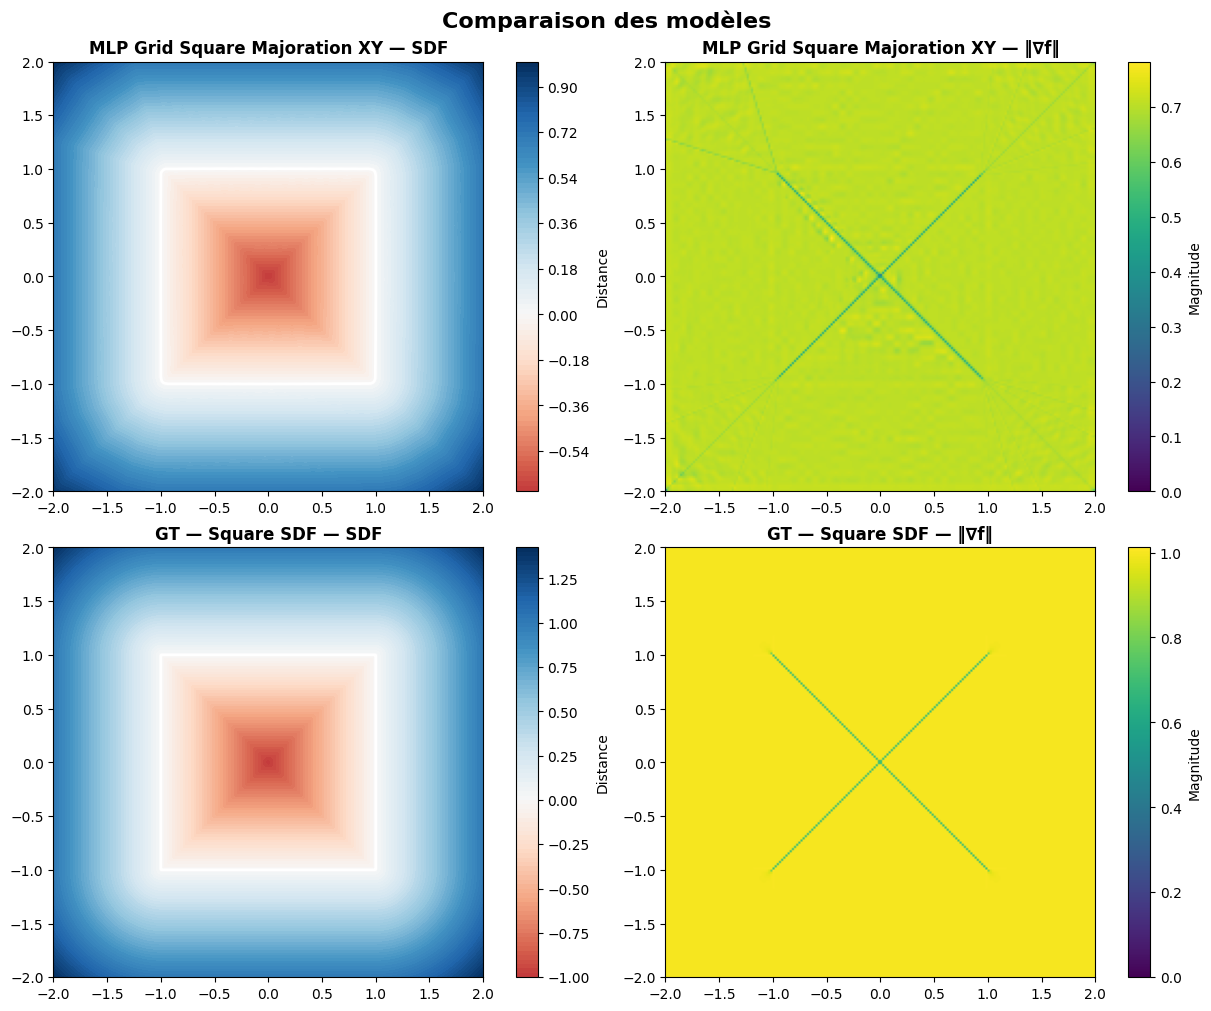

In [22]:
# loaded_model = load_model("trained-models/mlp_grid_square_majoration_XY.pt")
visualize_comparison(
    models=[(mlp_grid_square_majoration_XY, "MLP Grid Square Majoration XY")],
    sdf_funcs=[(lambda x, y: square(x, y, 1.0), "Square SDF")],
    grid_res=200
)

In [24]:
save_model(mlp_grid_square_majoration_XY, "trained-models/mlp_grid_square_majoration_XY.pt")

Modèle sauvegardé dans : trained-models/mlp_grid_square_majoration_XY.pt
